In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    make_scorer
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

In [26]:
df = pd.read_csv('titanic-lab2.csv')

print(df.shape)
print(df.head())

(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN    

In [27]:
print(df.info())

print('\nКоличество пропусков по колонкам:')
print(df.isnull().sum())

print('\nКоличество полных дубликатов строк:', df.duplicated().sum())

print('\nРаспределение целевой переменной Survived:')
print(df['Survived'].value_counts(normalize=True), end='\n\n')

print(df.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Количество пропусков по колонкам:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin         

In [28]:
df_clean = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

X = df_clean.drop(columns=['Survived'])
y = df_clean['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

age_median = X_train['Age'].median()
X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)

embarked_mode = X_train['Embarked'].mode()[0]
X_train['Embarked'] = X_train['Embarked'].fillna(embarked_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(embarked_mode)

X_train = pd.get_dummies(X_train, columns=['Sex', 'Embarked'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['Sex', 'Embarked'], drop_first=True)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)

experiments = {
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
        'params': {
            'max_depth': [3, 4, 5, 6, 8],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4]
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42, class_weight='balanced'),
        'params': {
            'n_estimators': [100, 150, 200],
            'max_depth': [4, 6, 8],
            'min_samples_split': [2, 5],
            'min_samples_leaf': [1, 2]
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100, 150],
            'learning_rate': [0.03, 0.05, 0.1],
            'max_depth': [2, 3, 4]
        }
    },
    'SVM': {
        'model': Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel='rbf', random_state=42, class_weight='balanced'))
        ]),
        'params': {
            'svm__C': [0.5, 1.0, 3.0, 5.0],
            'svm__gamma': ['scale', 'auto', 0.01, 0.1]
        }
    },
    'KNN': {
        'model': Pipeline([
            ('scaler', StandardScaler()),
            ('knn', KNeighborsClassifier())
        ]),
        'params': {
            'knn__n_neighbors': [3, 5, 7, 9, 11],
            'knn__weights': ['uniform', 'distance'],
            'knn__p': [1, 2]
        }
    }
}

best_models = {'Dummy Baseline': dummy_clf}

print("=== Поиск лучших гиперпараметров на X_train ===")
for name, exp in experiments.items():
    grid = GridSearchCV(
        estimator=exp['model'],
        param_grid=exp['params'],
        scoring='f1',
        cv=cv,
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_
    print(f"\n{name}:")
    print(f"  Лучший CV F1: {grid.best_score_:.4f}")
    print(f"  Лучшие параметры: {grid.best_params_}")

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0)
}
cv_summary = []

for name, model in best_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring_metrics)
    cv_summary.append({
        'Model': name,
        'CV Accuracy': f"{scores['test_accuracy'].mean():.4f} (±{scores['test_accuracy'].std():.3f})",
        'CV Precision': f"{scores['test_precision'].mean():.4f} (±{scores['test_precision'].std():.3f})",
        'CV Recall': f"{scores['test_recall'].mean():.4f} (±{scores['test_recall'].std():.3f})",
        'CV F1-score': f"{scores['test_f1'].mean():.4f} (±{scores['test_f1'].std():.3f})",
        'mean_f1': scores['test_f1'].mean()
    })

cv_table = pd.DataFrame(cv_summary).sort_values(by='mean_f1', ascending=False).drop(columns=['mean_f1'])
print("\n=== Результаты кросс-валидации настроенных моделей (5-Fold CV на Train) ===")
print(cv_table.to_string(index=False))

leaderboard_rows = []
test_predictions = {}

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    test_predictions[name] = y_pred

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    leaderboard_rows.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-score': round(f1, 4),
        'Порог F1 > 0.70': 'Пройден' if f1 > 0.70 else 'Не пройден'
    })

leaderboard = pd.DataFrame(leaderboard_rows).sort_values(by='F1-score', ascending=False).reset_index(drop=True)
print("\n=== Итоговый Leaderboard на тестовой выборке ===")
print(leaderboard.to_string(index=False))

=== Поиск лучших гиперпараметров на X_train ===

Decision Tree:
  Лучший CV F1: 0.7469
  Лучшие параметры: {'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 10}

Random Forest:
  Лучший CV F1: 0.7601
  Лучшие параметры: {'max_depth': 8, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}

Gradient Boosting:
  Лучший CV F1: 0.7686
  Лучшие параметры: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 150}

SVM:
  Лучший CV F1: 0.7552
  Лучшие параметры: {'svm__C': 5.0, 'svm__gamma': 0.1}

KNN:
  Лучший CV F1: 0.7424
  Лучшие параметры: {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}

=== Результаты кросс-валидации настроенных моделей (5-Fold CV на Train) ===
            Model     CV Accuracy    CV Precision       CV Recall     CV F1-score
Gradient Boosting 0.8329 (±0.025) 0.8238 (±0.056) 0.7215 (±0.015) 0.7686 (±0.030)
    Random Forest 0.8174 (±0.030) 0.7737 (±0.064) 0.7508 (±0.031) 0.7601 (±0.031)
              SVM 0.8188 (±0.026) 0.7850

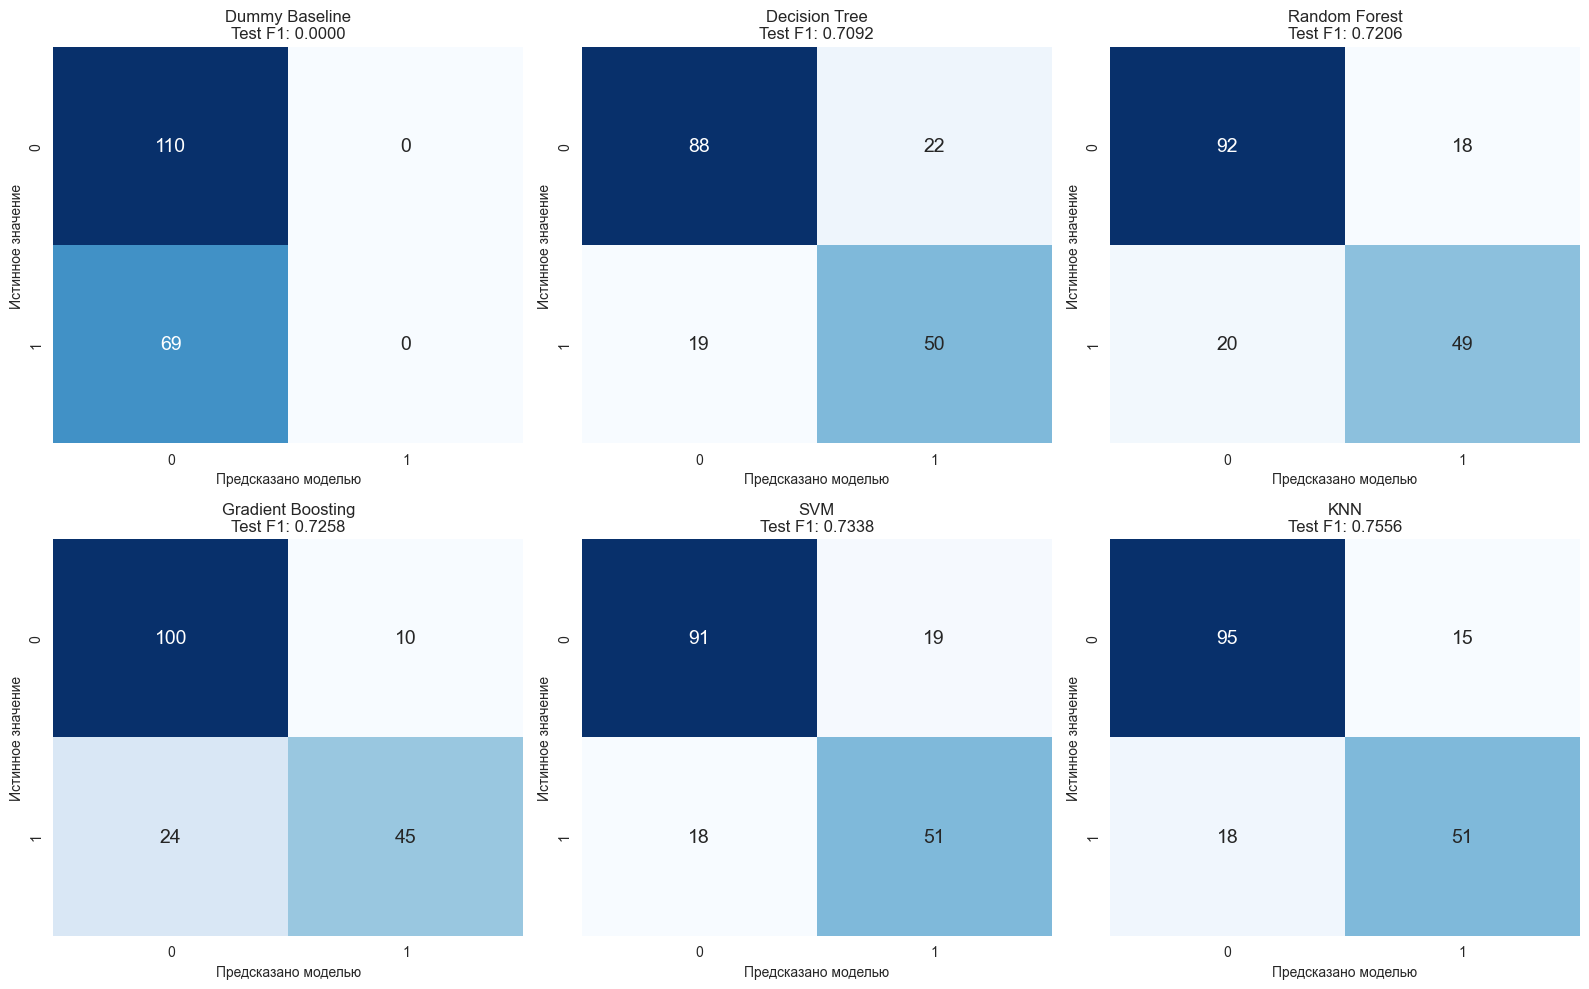

In [32]:
plt.figure(figsize=(16, 10))

for i, (name, y_pred) in enumerate(test_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    f1_val = f1_score(y_test, y_pred, zero_division=0)

    plt.subplot(2, 3, i + 1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                annot_kws={'size': 14})
    plt.title(f"{name}\nTest F1: {f1_val:.4f}", fontsize=12)
    plt.xlabel('Предсказано моделью')
    plt.ylabel('Истинное значение')

plt.tight_layout()
plt.show()

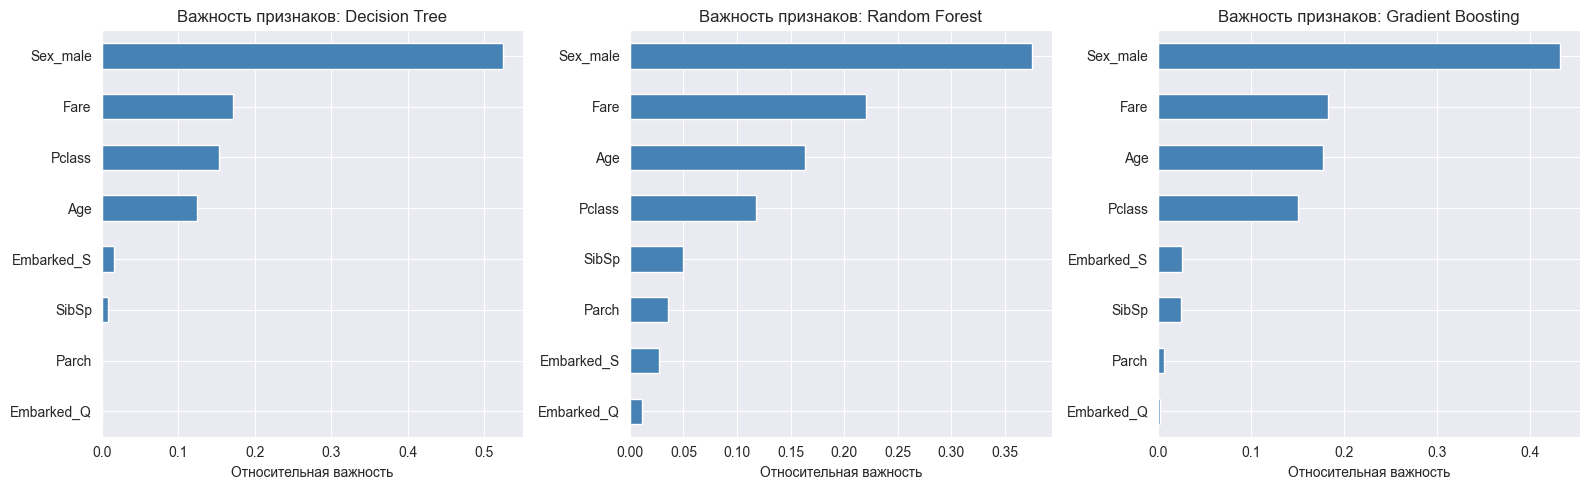

In [33]:
feature_names = X_train.columns

tree_models_for_importance = {
    'Decision Tree': best_models['Decision Tree'],
    'Random Forest': best_models['Random Forest'],
    'Gradient Boosting': best_models['Gradient Boosting']
}

plt.figure(figsize=(16, 5))

for i, (name, clf) in enumerate(tree_models_for_importance.items()):
    importances = pd.Series(clf.feature_importances_, index=feature_names).sort_values()

    plt.subplot(1, 3, i + 1)
    importances.plot(kind='barh', color='steelblue')
    plt.title(f"Важность признаков: {name}", fontsize=12)
    plt.xlabel('Относительная важность')

plt.tight_layout()
plt.show()

In [34]:
non_dummy_leaderboard = leaderboard[leaderboard['Model'] != 'Dummy Baseline']
best_model_name = non_dummy_leaderboard.iloc[0]['Model']
best_model_test_pred = test_predictions[best_model_name]

print(f"Лучшая модель по Leaderboard: {best_model_name}")

test_analysis = X_test.copy()
test_analysis['Actual'] = y_test.values
test_analysis['Predicted'] = best_model_test_pred
test_analysis['Is_Error'] = (test_analysis['Actual'] != test_analysis['Predicted'])

errors = test_analysis[test_analysis['Is_Error']].copy()
print(f"Всего ошибок на тесте: {len(errors)} из {len(y_test)} объектов")

fn_errors = errors[(errors['Actual'] == 1) & (errors['Predicted'] == 0)]
fp_errors = errors[(errors['Actual'] == 0) & (errors['Predicted'] == 1)]

print(f"Ошибок False Negative (погиб вместо выжил): {len(fn_errors)}")
print(f"Ошибок False Positive (выжил вместо погиб): {len(fp_errors)}")

print("\nПримеры объектов, на которых модель ошиблась:")
print(errors.head(6))

Лучшая модель по Leaderboard: KNN
Всего ошибок на тесте: 33 из 179 объектов
Ошибок False Negative (погиб вместо выжил): 18
Ошибок False Positive (выжил вместо погиб): 15

Примеры объектов, на которых модель ошиблась:
     Pclass   Age  SibSp  Parch      Fare  Sex_male  Embarked_Q  Embarked_S  \
553       3  22.0      0      0    7.2250      True       False       False   
559       3  36.0      1      0   17.4000     False       False        True   
698       1  49.0      1      1  110.8833      True       False       False   
27        1  19.0      3      2  263.0000      True       False        True   
279       3  35.0      1      1   20.2500     False       False        True   
712       1  48.0      1      0   52.0000      True       False        True   

     Actual  Predicted  Is_Error  
553       1          0      True  
559       1          0      True  
698       0          1      True  
27        0          1      True  
279       1          0      True  
712       1        